# 06 GLORYS12V1 sea-level predictors and transect attribution

**Manuscript outputs:** Figure S4, Tables B1 and B2; attributed transects used by stages 07 and 08

**Inputs:** GLORYS12V1 `zos` NetCDF, DSAS rates layer (ArcGIS output), study zones

Inputs are read from `Master_raw/`; everything produced is written to `Outputs/` (manuscript figures in `Outputs/Figures`, tables in `Outputs/Tables`). The first code cell lists every path. Run the cells in order.

# GLORYS12V1 Kenya: complete production workflow (Run All)

Reads original NetCDF and DSAS source, builds native GLORYS cells and attribution, assigns study zones by greatest line overlap, adds WGS84 representative Longitude/Latitude, and exports zoned GeoPackage, Shapefile, CSV and monthly cell time series. Original transect line geometry is preserved. The 145 nearest-ocean assignments remain provisional.

**Before Run All:** Close outputs in ArcGIS Pro/Excel. Archive or remove *generated outputs only* from an earlier run: midpoint GeoPackage, completed zoned GeoPackage/CSV, zoned Shapefile companion files, and monthly CSV. **Never delete the source DSAS GeoPackage, source NetCDF, or zone Shapefile.** This notebook intentionally refuses to overwrite existing outputs. It does not generate the old non-zoned completed outputs.


In [1]:
from pathlib import Path

# ------------------------------------------------------------
# REPOSITORY ROOT: first folder above this notebook that contains Master_raw
# (e.g. D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024)
# ------------------------------------------------------------
_here = Path.cwd().resolve()
ROOT = next((p for p in (_here, *_here.parents) if (p / "Master_raw").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError(f"No Master_raw folder found above {_here}. Open this notebook inside the repository.")
RAW = ROOT / "Master_raw"          # inputs
OUTPUTS = ROOT / "Outputs"         # everything this repository produces
FIGURES = OUTPUTS / "Figures"      # manuscript figures
TABLES = OUTPUTS / "Tables"        # manuscript tables
TEXT_STATS = TABLES / "Text_statistics"
for _d in (FIGURES, TABLES, TEXT_STATS):
    _d.mkdir(parents=True, exist_ok=True)
OVERWRITE = True                   # re-running replaces this notebook's earlier outputs


def first_existing(*candidates):
    """Return the first path that exists (otherwise the first one)."""
    for c in candidates:
        if Path(c).exists():
            return Path(c)
    return Path(candidates[0])


def save_table(df, name, index=False, folder=None):
    path = (folder or TABLES) / f"{name}.csv"
    df.to_csv(path, index=index, encoding="utf-8-sig")
    print("Saved:", path)


def save_figure(fig, name, dpi=600):
    for ext in ("jpg",):
        fig.savefig(FIGURES / f"{name}.{ext}", dpi=dpi, bbox_inches="tight", pil_kwargs=({"quality": 95} if ext == "jpg" else None))
    print("Saved:", FIGURES / f"{name}.jpg")


def remove_existing(*files):
    for f in map(Path, files):
        for t in (list(f.parent.glob(f.stem + ".*")) if f.suffix == ".shp" else [f]):
            if t.exists():
                if not OVERWRITE:
                    raise FileExistsError(t)
                t.unlink()

# ------------------------------------------------------------
# INPUTS AND OUTPUT FOLDERS FOR THIS NOTEBOOK
# ------------------------------------------------------------
TRANSECT_RATES_DIR = RAW / "Transect_rates"
DSAS_RATES_GPKG = TRANSECT_RATES_DIR / "ke_30mtr_transects_dsas_uncy.gpkg"
DSAS_RATES_LAYER = "ke_30mtr_transect_dsas_uncy_final_rates_20260915_112207"
GLORYS_NC = RAW / "Sea_Surface_height" / "GLORYS12V1_zos_Kenya_1995_2025_monthly.nc"
BASE_MAPS = RAW / "Study_zones"
STUDY_ZONES_SHP = BASE_MAPS / "Study_zones_kwale_mom_Tana.shp"
GLORYS_DIR = OUTPUTS / "GLORYS_attribution"
SPATIAL_DIR = GLORYS_DIR
GLORYS_MIDPOINT_GPKG = GLORYS_DIR / "ke_transects_GLORYS_midpoint_attributed.gpkg"
GLORYS_REFPOINT_PNG = GLORYS_DIR / "GLORYS_DSAS_reference_points_static.jpg"
COMPLETE_LAYER = "transects_complete"
COMPLETE_GPKG = GLORYS_DIR / "ke_transects_GLORYS_complete_attribution_zoned.gpkg"
COMPLETE_CSV = GLORYS_DIR / "ke_transects_GLORYS_complete_analysis_input_zoned.csv"
COMPLETE_SHP_DIR = GLORYS_DIR / "GLORYS_Transects_Shapefile"
COMPLETE_SHP = COMPLETE_SHP_DIR / "ke_transects_GLORYS_complete_zoned.shp"
GLORYS_MONTHLY_CSV = GLORYS_DIR / "ke_GLORYS_coastal_pixels_monthly_1995_2025.csv"

# Create this notebook's output folders before anything is saved
GLORYS_DIR.mkdir(parents=True, exist_ok=True)
COMPLETE_SHP_DIR.mkdir(parents=True, exist_ok=True)

print("Repository root:", ROOT)
for _label, _p in [("GLORYS_NC", GLORYS_NC), ("DSAS_RATES_GPKG", DSAS_RATES_GPKG), ("STUDY_ZONES_SHP", STUDY_ZONES_SHP)]:
    print(f"  {'ok     ' if _p.exists() else 'MISSING'} {_label}: {_p}")

import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.stats import linregress
from shapely.geometry import box


NC_PATH = GLORYS_NC
DSAS_GPKG = DSAS_RATES_GPKG
DSAS_LAYER = DSAS_RATES_LAYER
OUTPUT_GPKG = GLORYS_MIDPOINT_GPKG
OUTPUT_MAP = GLORYS_REFPOINT_PNG

assert NC_PATH.is_file(), f"NetCDF not found: {NC_PATH}"
assert DSAS_GPKG.is_file(), f"DSAS GeoPackage not found: {DSAS_GPKG}"
assert OUTPUT_GPKG.resolve() != DSAS_GPKG.resolve(), "Output must not overwrite the source"
print('NetCDF:', NC_PATH)
print('DSAS source:', DSAS_GPKG)
print('New output:', OUTPUT_GPKG)

Repository root: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024
  ok      GLORYS_NC: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Master_raw\Sea_Surface_height\GLORYS12V1_zos_Kenya_1995_2025_monthly.nc
  ok      DSAS_RATES_GPKG: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Master_raw\Transect_rates\ke_30mtr_transects_dsas_uncy.gpkg
  ok      STUDY_ZONES_SHP: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Master_raw\Study_zones\Study_zones_kwale_mom_Tana.shp
NetCDF: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Master_raw\Sea_Surface_height\GLORYS12V1_zos_Kenya_1995_2025_monthly.nc
DSAS source: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Master_raw\Transect_rates\ke_30mtr_transects_dsas_uncy.gpkg
New output: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\GLORYS_attribution\ke_transects_GLORYS_midpoint_attributed.gpkg


## 1. Load and validate monthly GLORYS sea level

In [2]:
ds = xr.open_dataset(NC_PATH)
zos = ds["zos"].transpose("time", "latitude", "longitude")
expected = pd.period_range("1995-01", "2025-12", freq="M")
actual = pd.PeriodIndex(pd.to_datetime(ds.time.values), freq="M")
assert len(actual) == len(expected) and actual.equals(expected), "Missing, extra or out-of-order months"
assert ds.longitude.size >= 2 and ds.latitude.size >= 2
valid_cells = zos.notnull().any("time").transpose("latitude", "longitude")
annual_zos = zos.groupby("time.year").mean("time", skipna=True)
print('Months:', len(actual), '| Valid native ocean cells:', int(valid_cells.sum()))
print('Native longitude/latitude:', ds.longitude.size, ds.latitude.size)

Months: 372 | Valid native ocean cells: 474
Native longitude/latitude: 27 32


## 2. Derive the two native-cell predictors

In [3]:
years = annual_zos.year.values.astype(float)
def cell_metrics(values):
    ok = np.isfinite(values)
    if ok.sum() < 3:
        return np.array([np.nan, np.nan], dtype=float)
    result = linregress(years[ok], values[ok])
    residual = values[ok] - (result.intercept + result.slope * years[ok])
    return np.array([result.slope * 1000, np.std(residual, ddof=1)])

metrics = xr.apply_ufunc(
    cell_metrics, annual_zos, input_core_dims=[["year"]],
    output_core_dims=[["metric"]], vectorize=True,
    output_dtypes=[float], dask="parallelized",
    dask_gufunc_kwargs={"output_sizes": {"metric": 2}},
).assign_coords(metric=["trend_mm_yr", "variability_m"])
trend = metrics.sel(metric="trend_mm_yr").transpose("latitude", "longitude")
variability = metrics.sel(metric="variability_m").transpose("latitude", "longitude")
assert np.array_equal(np.isfinite(trend.values), np.isfinite(variability.values)), "Predictor masks differ"
assert np.array_equal(np.isfinite(trend.values), valid_cells.values), "Predictor and ocean masks differ"
print('Predictor 1: SL_Trend_mm_yr (mm/year)')
print('Predictor 2: SL_Variability_m (detrended annual SD, metres)')

Predictor 1: SL_Trend_mm_yr (mm/year)
Predictor 2: SL_Variability_m (detrended annual SD, metres)


## 3. Read rate-bearing DSAS transects and construct native GLORYS polygons

In [4]:
transects = gpd.read_file(DSAS_GPKG, layer=DSAS_LAYER)
assert transects.crs is not None and transects.crs.is_projected, "Transects require a projected CRS for length midpoints"
assert transects.geometry.notna().all() and (~transects.geometry.is_empty).all()
assert transects.geom_type.eq('LineString').all(), "Inspect unexpected geometry types"
assert not transects.columns.intersection(['Transect_ID', 'Pixel_ID', 'Assignment_Status', 'SL_Trend_mm_yr', 'SL_Variability_m']).size, "Input already has attribution columns: inspect before rerunning"
transects = transects.reset_index(drop=True).copy()
transects['Transect_ID'] = np.arange(1, len(transects) + 1)

def cell_edges(coords):
    coords = np.asarray(coords, dtype=float)
    assert np.all(np.diff(coords) > 0), "Grid coordinates must increase"
    edges = np.empty(len(coords) + 1)
    edges[1:-1] = (coords[:-1] + coords[1:]) / 2
    edges[0] = coords[0] - (coords[1] - coords[0]) / 2
    edges[-1] = coords[-1] + (coords[-1] - coords[-2]) / 2
    return edges

lons = trend.longitude.values
lats = trend.latitude.values
lon_edges, lat_edges = cell_edges(lons), cell_edges(lats)
records = []
for iy, lat in enumerate(lats):
    for ix, lon in enumerate(lons):
        t, v = float(trend.values[iy, ix]), float(variability.values[iy, ix])
        if not np.isfinite(t):
            continue
        records.append(dict(Pixel_ID=f'R{iy:03d}_C{ix:03d}', Grid_Row=iy, Grid_Col=ix,
            Grid_Lon=float(lon), Grid_Lat=float(lat), SL_Trend_mm_yr=t, SL_Variability_m=v,
            geometry=box(lon_edges[ix], lat_edges[iy], lon_edges[ix+1], lat_edges[iy+1])))
glorys_grid = gpd.GeoDataFrame(records, crs='EPSG:4326')
assert glorys_grid.Pixel_ID.is_unique
print('Rate-bearing transects:', len(transects), '| Valid GLORYS polygons:', len(glorys_grid))

Rate-bearing transects: 12455 | Valid GLORYS polygons: 474


## 4. Representative points and static overlay map

Saved: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Figures\Figure_S4_GLORYS_grid_and_transect_reference_points.jpg


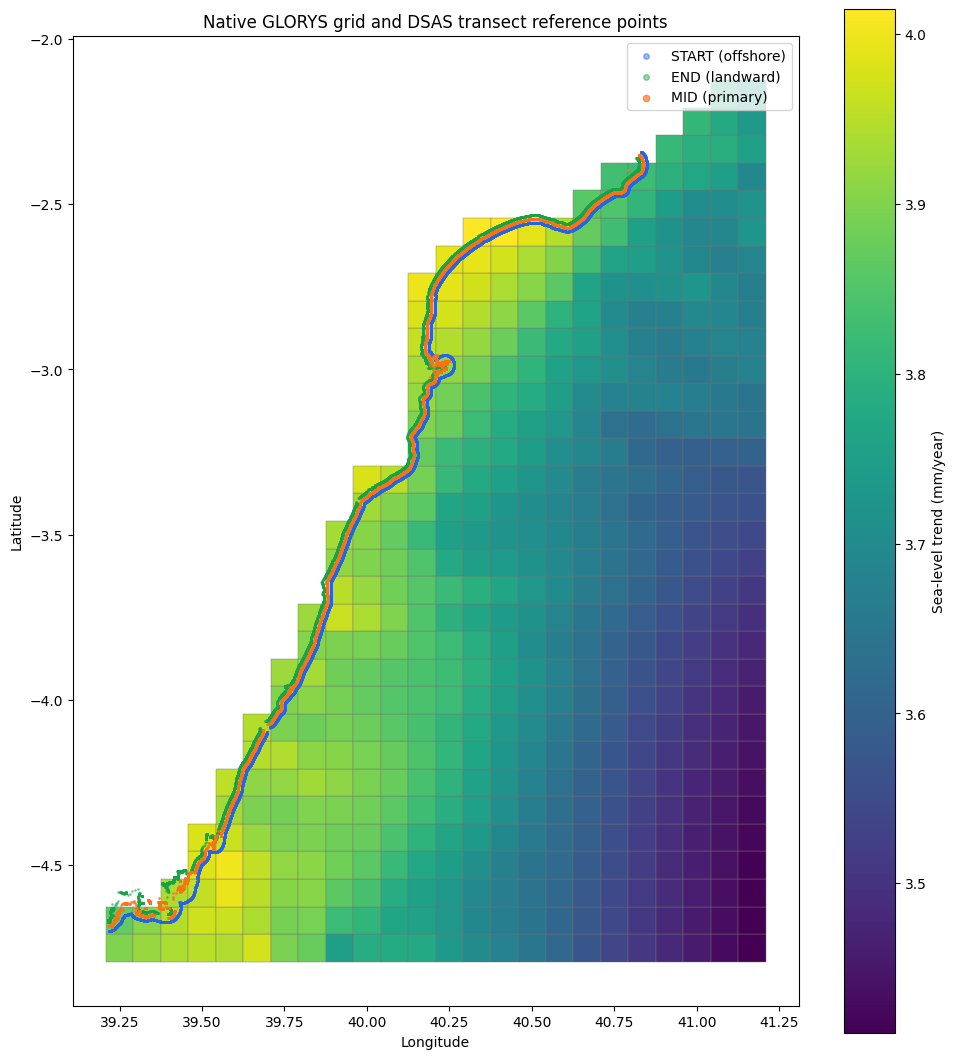

Static map: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\GLORYS_attribution\GLORYS_DSAS_reference_points_static.jpg


In [5]:
def reference_points(fraction):
    pts = gpd.GeoDataFrame(
        transects[['Transect_ID']].copy(),
        geometry=transects.geometry.apply(lambda line: line.interpolate(fraction, normalized=True)),
        crs=transects.crs,
    )
    return pts.to_crs('EPSG:4326')

start_wgs = reference_points(0)
mid_wgs = reference_points(0.5)
end_wgs = reference_points(1)

fig, ax = plt.subplots(figsize=(10, 11))
glorys_grid.plot(column='SL_Trend_mm_yr', ax=ax, cmap='viridis', legend=True,
    legend_kwds={'label': 'Sea-level trend (mm/year)'}, edgecolor='0.45', linewidth=0.3)
# Display all three locations, with MID plotted last for legibility.
start_wgs.plot(ax=ax, color='#2563eb', markersize=1, alpha=0.45, label='START (offshore)')
end_wgs.plot(ax=ax, color='#16a34a', markersize=1, alpha=0.45, label='END (landward)')
mid_wgs.plot(ax=ax, color='#f97316', markersize=1.3, alpha=0.65, label='MID (primary)')
ax.set(title='Native GLORYS grid and DSAS transect reference points', xlabel='Longitude', ylabel='Latitude')
ax.legend(loc='best', markerscale=4)
plt.tight_layout()
fig.savefig(OUTPUT_MAP, dpi=250, bbox_inches='tight', pil_kwargs={"quality": 95})
save_figure(fig, "Figure_S4_GLORYS_grid_and_transect_reference_points", dpi=300)
plt.show()
print('Static map:', OUTPUT_MAP)


## 5. Complete midpoint attribution audit (no automatic fallback)

Point-in-polygon matching uses native valid-cell polygons. START is checked only to classify unassigned midpoints; no offshore fallback is applied. Null predictor values are intentional for unresolved cases.

In [6]:
fields = ['Pixel_ID', 'Grid_Row', 'Grid_Col', 'Grid_Lon', 'Grid_Lat',
          'SL_Trend_mm_yr', 'SL_Variability_m', 'geometry']
mid_join = gpd.sjoin(mid_wgs, glorys_grid[fields], how='left', predicate='within')
start_join = gpd.sjoin(start_wgs, glorys_grid[['Pixel_ID', 'geometry']], how='left', predicate='within')
assert len(mid_join) == len(transects) and mid_join.Transect_ID.is_unique, 'Midpoint duplicates: check boundary points'
assert len(start_join) == len(transects) and start_join.Transect_ID.is_unique, 'START duplicates: check boundary points'

mid_join = mid_join.drop(columns=['index_right'])
start_status = start_join[['Transect_ID', 'Pixel_ID']].rename(columns={'Pixel_ID':'START_Pixel_ID'})
audit = mid_join.drop(columns='geometry').merge(start_status, on='Transect_ID', validate='one_to_one')
audit['MID_Lon'] = mid_join.geometry.x.to_numpy()
audit['MID_Lat'] = mid_join.geometry.y.to_numpy()
audit['QC_class'] = np.select(
    [audit.Pixel_ID.notna(), audit.START_Pixel_ID.notna()],
    ['MID_VALID', 'MID_INVALID_START_VALID'], default='BOTH_INVALID')
audit['Assignment_Status'] = np.select(
    [audit.Pixel_ID.notna(), audit.START_Pixel_ID.notna()],
    ['DIRECT_MID', 'REVIEW_START_FALLBACK'], default='REVIEW_BOTH_INVALID')
audit['Reference_Method'] = np.where(audit.Pixel_ID.notna(), 'MID', 'UNASSIGNED')
audit = audit.drop(columns=['START_Pixel_ID'])  # classification only; no fallback value exported
assert len(audit) == len(transects) and audit.Transect_ID.is_unique
assert audit.loc[audit.Pixel_ID.isna(), ['SL_Trend_mm_yr','SL_Variability_m']].isna().all().all()
assert audit.loc[audit.Pixel_ID.notna(), ['SL_Trend_mm_yr','SL_Variability_m']].notna().all().all()
print('Complete audit:', len(audit))
print(audit.Assignment_Status.value_counts().to_string())
print('Directly represented coastal cells:', audit.Pixel_ID.nunique())
display(audit.head())

Complete audit: 12455
Assignment_Status
DIRECT_MID               12102
REVIEW_START_FALLBACK      208
REVIEW_BOTH_INVALID        145
Directly represented coastal cells: 46


,Transect_ID,Pixel_ID,Grid_Row,Grid_Col,Grid_Lon,Grid_Lat,SL_Trend_mm_yr,SL_Variability_m,MID_Lon,MID_Lat,QC_class,Assignment_Status,Reference_Method
0,1,R028_C022,28.0,22.0,40.833332,-2.416667,3.827448,0.027139,40.792408,-2.397082,MID_VALID,DIRECT_MID,MID
1,2,R028_C022,28.0,22.0,40.833332,-2.416667,3.827448,0.027139,40.792425,-2.397099,MID_VALID,DIRECT_MID,MID
2,3,R028_C022,28.0,22.0,40.833332,-2.416667,3.827448,0.027139,40.792491,-2.397129,MID_VALID,DIRECT_MID,MID
3,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.823512,-2.351128,BOTH_INVALID,REVIEW_BOTH_INVALID,UNASSIGNED
4,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.823706,-2.351241,BOTH_INVALID,REVIEW_BOTH_INVALID,UNASSIGNED


## 6. Preserve the midpoint-only audit GeoPackage

This is an **intermediate provenance snapshot**, not the final analysis dataset. It intentionally contains 353 missing predictor assignments. Retain the GeoPackage for audit/sensitivity comparisons; do not use its transect layer as the completed analysis input. The final attribution and exports are created in Section 9.


In [7]:
attribution_fields = ['Transect_ID', 'MID_Lon', 'MID_Lat', 'Pixel_ID', 'Grid_Row', 'Grid_Col',
    'Grid_Lon', 'Grid_Lat', 'SL_Trend_mm_yr', 'SL_Variability_m', 'QC_class',
    'Assignment_Status', 'Reference_Method']
attributed = transects.merge(audit[attribution_fields], on='Transect_ID', how='left', validate='one_to_one')
assert len(attributed) == len(transects)
assert attributed.geometry.equals(transects.geometry), 'Original geometry changed'
assert attributed.Assignment_Status.notna().all()
# Remove the previous generated GeoPackage before recreating it.
# This is the intermediate midpoint-attribution output,
# NOT the original DSAS source GeoPackage.
if OUTPUT_GPKG.exists():
    OUTPUT_GPKG.unlink()
    print("Removed previous generated output:", OUTPUT_GPKG)

# Keep the audit as spatial points so exceptional locations remain inspectable.
audit_points = mid_wgs[['Transect_ID', 'geometry']].merge(audit, on='Transect_ID', validate='one_to_one')
try:
    attributed.to_file(OUTPUT_GPKG, layer='transects_attributed', driver='GPKG')
    glorys_grid.to_file(OUTPUT_GPKG, layer='glorys_native_grid', driver='GPKG', mode='a')
    audit_points.to_file(OUTPUT_GPKG, layer='midpoint_audit', driver='GPKG', mode='a')
except Exception:
    print('Export interrupted; inspect/remove incomplete NEW output before rerunning:', OUTPUT_GPKG)
    raise

import pyogrio
print('Saved:', OUTPUT_GPKG)
print('Layers:', pyogrio.list_layers(OUTPUT_GPKG).tolist())
print('Transects:', len(attributed), '| Direct:', int(attributed.Pixel_ID.notna().sum()),
      '| Unassigned:', int(attributed.Pixel_ID.isna().sum()))

Removed previous generated output: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\GLORYS_attribution\ke_transects_GLORYS_midpoint_attributed.gpkg
Saved: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\GLORYS_attribution\ke_transects_GLORYS_midpoint_attributed.gpkg
Layers: [['transects_attributed', 'LineString'], ['glorys_native_grid', 'Polygon'], ['midpoint_audit', 'Point']]
Transects: 12455 | Direct: 12102 | Unassigned: 353


## 7. Midpoint audit interpretation

Section 5 records valid midpoint assignments and masked locations. Section 6 preserves those results without fallback. The controlled fallback in Section 9 completes the 208 valid offshore START assignments and provisionally assigns 145 remaining transects to the nearest valid cell. All 145 nearest candidates previously matched `R028_C022`, up to approximately 3.76 km from its polygon boundary; coastline connectivity has **not** been verified. Keep the provisional status and assess sensitivity to excluding those transects. For spatial inference, aggregate shoreline-change observations by native `Pixel_ID`; multiple transects within one cell are not independent sea-level observations.


## 8. Controlled offshore fallback: methodological note

Attribution priority is **MID (12,102)**, **START (208)**, then **nearest valid ocean cell from START (145, provisional)**. No interpolation or downscaling is performed. `Original_MID_Pixel_ID`, `Reference_Method`, `Assignment_Status` and `Fallback_Distance_km` preserve attribution provenance. Nearest distances measure the projected distance from the START point to the valid-cell **polygon boundary**, not to its centre. The provisional 145 assignments require a coastline/water-connectivity review before definitive inference.


In [8]:
# ============================================================
# 9. COMPLETE GLORYS ATTRIBUTION AND EXPORT
# ============================================================
# PURPOSE
# Complete sea-level attribution for all 12,455 DSAS transects
# and export the updated spatial and attribute datasets.
#
# ATTRIBUTION HIERARCHY
# 1. MID:
#    Retain existing valid midpoint assignments (12,102).
#
# 2. START:
#    For masked midpoints, use the valid offshore START cell
#    (208 transects).
#
# 3. NEAREST_OCEAN:
#    For remaining masked START points, assign the nearest
#    valid GLORYS ocean cell (145 transects).
#
# PREVIOUS DIAGNOSTIC FINDINGS
# - All 145 nearest candidates matched R028_C022.
# - Maximum distance to valid cell boundary: 3.759394 km.
# - Nearest assignments remain PROVISIONAL pending coastline
#   connectivity review.
#
# No sea-level interpolation or downscaling is performed.
# Original midpoint-only files are preserved.
#
# OUTPUTS
# - Completed GeoPackage
# - Completed CSV
# - Validation of exported records and predictors
# ============================================================

from pathlib import Path

import geopandas as gpd
import pandas as pd
import numpy as np


# ============================================================
# 9.1 CONFIGURATION
# ============================================================

CRS_METRIC = "EPSG:32737"

INPUT_GPKG = GLORYS_MIDPOINT_GPKG

OUTPUT_DIR = SPATIAL_DIR

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_GPKG = COMPLETE_GPKG

OUTPUT_CSV = COMPLETE_CSV

INPUT_LAYER = "transects_attributed"
OUTPUT_LAYER = "transects_complete"

GRID_ATTRIBUTES = [
    "Pixel_ID",
    "Grid_Row",
    "Grid_Col",
    "Grid_Lon",
    "Grid_Lat",
    "SL_Trend_mm_yr",
    "SL_Variability_m",
]

PREDICTOR_FIELDS = [
    "SL_Trend_mm_yr",
    "SL_Variability_m",
]


# ============================================================
# 9.2 PREPARE WORKING DATA
# ============================================================

# These objects must already exist from Sections 3–5:
# audit, glorys_grid, start_wgs

completed_audit = audit.copy()
grid = glorys_grid.copy()
starts = start_wgs.copy()

required_inputs = [
    (
        "audit",
        completed_audit,
        {
            "Transect_ID",
            "Pixel_ID",
            "Assignment_Status",
        },
    ),
    (
        "glorys_grid",
        grid,
        set(GRID_ATTRIBUTES) | {"geometry"},
    ),
    (
        "start_wgs",
        starts,
        {"Transect_ID", "geometry"},
    ),
]

for name, frame, required in required_inputs:

    missing = required - set(frame.columns)

    if missing:
        raise ValueError(
            f"{name} is missing columns: {sorted(missing)}"
        )

if len(completed_audit) != 12455:
    raise ValueError("Unexpected number of audit records.")

if not completed_audit["Transect_ID"].is_unique:
    raise ValueError("Duplicate audit Transect_ID values.")

if not starts["Transect_ID"].is_unique:
    raise ValueError("Duplicate START Transect_ID values.")

if not grid["Pixel_ID"].is_unique:
    raise ValueError("Duplicate GLORYS Pixel_ID values.")

if starts.crs is None or grid.crs is None:
    raise ValueError("Missing coordinate reference system.")

# Preserve original midpoint attribution
completed_audit["Original_MID_Pixel_ID"] = (
    completed_audit["Pixel_ID"].copy()
)

completed_audit["Fallback_Distance_km"] = np.nan

completed_audit["Reference_Method"] = np.where(
    completed_audit["Pixel_ID"].notna(),
    "MID",
    "UNASSIGNED",
)


# ============================================================
# 9.3 IDENTIFY UNASSIGNED TRANSECTS
# ============================================================

unassigned_ids = completed_audit.loc[
    completed_audit["Pixel_ID"].isna(),
    ["Transect_ID"],
].copy()

if len(unassigned_ids) != 353:
    raise ValueError(
        "Expected 353 unresolved midpoint assignments; "
        f"found {len(unassigned_ids)}."
    )

start_candidates = starts[["Transect_ID", "geometry"]].merge(
    unassigned_ids,
    on="Transect_ID",
    how="inner",
    validate="one_to_one",
)

if len(start_candidates) != 353:
    raise ValueError(
        "Not all unresolved transects have START points."
    )

# Project geometries for distance calculations
start_metric = start_candidates.to_crs(CRS_METRIC)

grid_metric = grid[["Pixel_ID", "geometry"]].to_crs(CRS_METRIC)


# ============================================================
# 9.4 DIRECT START ATTRIBUTION
# ============================================================

start_join = gpd.sjoin(
    start_metric,
    grid_metric[
        ["Pixel_ID", "geometry"]
    ],
    how="left",
    predicate="within",
)

if len(start_join) != 353:
    raise ValueError(
        "Unexpected START spatial-join record count."
    )

if not start_join["Transect_ID"].is_unique:
    raise ValueError(
        "Duplicate START assignments detected."
    )

direct_start = start_join.loc[
    start_join["Pixel_ID"].notna(),
    ["Transect_ID", "Pixel_ID"],
].copy()

if len(direct_start) != 208:
    raise ValueError(
        "Expected 208 direct START assignments; "
        f"found {len(direct_start)}."
    )


# ============================================================
# 9.5 NEAREST VALID OCEAN CELL
# ============================================================

remaining = start_join.loc[
    start_join["Pixel_ID"].isna(),
    ["Transect_ID", "geometry"],
].copy()

remaining = gpd.GeoDataFrame(
    remaining,
    geometry="geometry",
    crs=CRS_METRIC,
)

if len(remaining) != 145:
    raise ValueError(
        "Expected 145 remaining transects; "
        f"found {len(remaining)}."
    )

nearest_join = gpd.sjoin_nearest(
    remaining,
    grid_metric[
        ["Pixel_ID", "geometry"]
    ],
    how="left",
    distance_col="Distance_m",
)

if len(nearest_join) != 145:
    raise ValueError(
        "Unexpected nearest-neighbour record count."
    )

if not nearest_join["Transect_ID"].is_unique:
    raise ValueError(
        "Duplicate nearest-neighbour matches detected."
    )

if nearest_join["Pixel_ID"].isna().any():
    raise ValueError(
        "Some nearest-neighbour assignments are missing."
    )

nearest_join["Fallback_Distance_km"] = (
    nearest_join["Distance_m"] / 1000
)

# Verify previous diagnostic results
if not nearest_join["Pixel_ID"].eq(
    "R028_C022"
).all():
    raise ValueError(
        "Nearest-cell results differ from previous diagnostics."
    )

maximum_distance = (
    nearest_join["Fallback_Distance_km"].max()
)

if not np.isclose(
    maximum_distance,
    3.759394,
    atol=0.001,
):
    raise ValueError(
        "Nearest-cell distances differ from previous diagnostics."
    )


# ============================================================
# 9.6 UPDATE COMPLETE ATTRIBUTION TABLE
# ============================================================

completed_audit = completed_audit.set_index(
    "Transect_ID"
)

start_values = direct_start.set_index(
    "Transect_ID"
)

nearest_values = nearest_join.set_index(
    "Transect_ID"
)

# Direct START fallback
completed_audit.loc[
    start_values.index,
    "Pixel_ID",
] = start_values["Pixel_ID"]

completed_audit.loc[
    start_values.index,
    "Assignment_Status",
] = "DIRECT_START"

completed_audit.loc[
    start_values.index,
    "Reference_Method",
] = "START"

# Nearest-cell fallback
completed_audit.loc[
    nearest_values.index,
    "Pixel_ID",
] = nearest_values["Pixel_ID"]

completed_audit.loc[
    nearest_values.index,
    "Assignment_Status",
] = "NEAREST_OCEAN_PROVISIONAL"

completed_audit.loc[
    nearest_values.index,
    "Reference_Method",
] = "NEAREST_OCEAN"

completed_audit.loc[
    nearest_values.index,
    "Fallback_Distance_km",
] = nearest_values["Fallback_Distance_km"]


# ============================================================
# 9.7 TRANSFER GLORYS ATTRIBUTES AND BOTH PREDICTORS
# ============================================================

cell_lookup = grid.set_index("Pixel_ID")

assigned_cells = completed_audit["Pixel_ID"]

for field in GRID_ATTRIBUTES[1:]:

    completed_audit[field] = assigned_cells.map(
        cell_lookup[field]
    )

completed_audit = completed_audit.reset_index()


# ============================================================
# 9.8 VALIDATE COMPLETED ATTRIBUTION
# ============================================================

expected_status = {
    "DIRECT_MID": 12102,
    "DIRECT_START": 208,
    "NEAREST_OCEAN_PROVISIONAL": 145,
}

actual_status = (
    completed_audit["Assignment_Status"]
    .value_counts()
    .to_dict()
)

if actual_status != expected_status:
    raise ValueError(
        "Unexpected assignment status counts: "
        f"{actual_status}"
    )

if len(completed_audit) != 12455:
    raise ValueError(
        "Completed audit does not contain 12,455 records."
    )

if not completed_audit["Transect_ID"].is_unique:
    raise ValueError(
        "Duplicate Transect_ID values in completed audit."
    )

if not completed_audit[
    GRID_ATTRIBUTES
].notna().all().all():
    raise ValueError(
        "Completed attribution still contains missing GLORYS values."
    )

# Confirm original MID assignments were preserved
mid_records = completed_audit.loc[
    completed_audit["Assignment_Status"] == "DIRECT_MID"
]

if not (
    mid_records["Pixel_ID"]
    == mid_records["Original_MID_Pixel_ID"]
).all():
    raise ValueError(
        "Original midpoint assignments were modified."
    )


# ============================================================
# 9.9 LOAD ORIGINAL TRANSECT GEOMETRIES
# ============================================================

if not INPUT_GPKG.exists():
    raise FileNotFoundError(INPUT_GPKG)

transects_original = gpd.read_file(
    INPUT_GPKG,
    layer=INPUT_LAYER,
)

if len(transects_original) != 12455:
    raise ValueError(
        "Unexpected number of original transects."
    )

if not transects_original["Transect_ID"].is_unique:
    raise ValueError(
        "Duplicate Transect_ID values in original GeoPackage."
    )


# ============================================================
# 9.10 JOIN COMPLETED ATTRIBUTION TO TRANSECTS
# ============================================================

attribution_fields = [
    "Pixel_ID",
    "Grid_Row",
    "Grid_Col",
    "Grid_Lon",
    "Grid_Lat",
    "SL_Trend_mm_yr",
    "SL_Variability_m",
    "QC_class",
    "Assignment_Status",
    "Reference_Method",
    "Original_MID_Pixel_ID",
    "Fallback_Distance_km",
]

# Remove outdated attribution columns from original layer
existing_fields = [
    field
    for field in attribution_fields
    if field in transects_original.columns
]

transects_clean = transects_original.drop(
    columns=existing_fields
)

# Transfer completed attribution
transfer_fields = [
    "Transect_ID"
] + attribution_fields

missing_fields = (
    set(transfer_fields)
    - set(completed_audit.columns)
)

if missing_fields:
    raise ValueError(
        "Completed audit is missing: "
        f"{sorted(missing_fields)}"
    )

transects_complete = transects_clean.merge(
    completed_audit[transfer_fields],
    on="Transect_ID",
    how="left",
    validate="one_to_one",
)

transects_complete = gpd.GeoDataFrame(
    transects_complete,
    geometry="geometry",
    crs=transects_original.crs,
)


# ============================================================
# 9.11 VALIDATE FINAL SPATIAL DATASET
# ============================================================

if len(transects_complete) != 12455:
    raise ValueError(
        "The spatial join changed the transect count."
    )

if not transects_complete[
    GRID_ATTRIBUTES
].notna().all().all():
    raise ValueError(
        "Missing GLORYS attributes remain after joining."
    )

if transects_complete.geometry.isna().any() or transects_complete.geometry.is_empty.any():
    raise ValueError(
        "Some transect geometries are missing."
    )

if not transects_complete["Transect_ID"].is_unique:
    raise ValueError(
        "Duplicate transects detected after joining."
    )

# Confirm original geometries and shoreline-rate values survive the join.
if not transects_complete.geometry.equals(transects_original.geometry):
    raise ValueError("Transect geometries changed during attribution join.")

# Preserve DSAS rate fields
required_rates = [
    "WLR",
    "EPR",
    "NSM",
    "LCI90",
]

missing_rates = (
    set(required_rates)
    - set(transects_complete.columns)
)

if missing_rates:
    raise ValueError(
        f"Missing DSAS fields: {sorted(missing_rates)}"
    )

for rate in required_rates:
    if not transects_complete[rate].equals(transects_original[rate]):
        raise ValueError(f"Original DSAS field changed: {rate}")


# ============================================================
# 9.12 ASSIGN STUDY ZONES FROM ORIGINAL TRANSECT LINES
# ============================================================
# For overlapping zones, use the greatest positive intersecting
# line length. Stop for unmatched transects or near-equal ties.
ZONE_SHP = STUDY_ZONES_SHP
if not ZONE_SHP.is_file():
    raise FileNotFoundError(f"Full study-zone shapefile missing: {ZONE_SHP}")
zones = gpd.read_file(ZONE_SHP)
if zones.crs is None or transects_complete.crs is None:
    raise ValueError("Missing CRS on zone or transect dataset")
if "Name" not in zones or zones["Name"].isna().any() or zones["Name"].astype(str).str.strip().eq("").any():
    raise ValueError("Study zones require a nonblank Name field")
if zones.geometry.isna().any() or zones.geometry.is_empty.any() or not zones.geometry.is_valid.all():
    raise ValueError("Study-zone geometry is missing, empty or invalid")
if transects_complete["Transect_ID"].duplicated().any():
    raise ValueError("Duplicate Transect_ID")
zone_metric = zones[["Name", "geometry"]].to_crs(CRS_METRIC).dissolve(by="Name", as_index=False)
line_metric = transects_complete[["Transect_ID", "geometry"]].to_crs(CRS_METRIC)
zone_hits = gpd.sjoin(line_metric, zone_metric, how="left", predicate="intersects")
zone_geoms = zone_metric.set_index("Name").geometry
zone_hits["Overlap_m"] = zone_hits.apply(
    lambda row: 0.0 if pd.isna(row["Name"]) else row.geometry.intersection(zone_geoms.loc[row["Name"]]).length,
    axis=1,
)
positive = zone_hits.loc[zone_hits["Overlap_m"] > 0].copy()
missing_ids = set(line_metric["Transect_ID"]) - set(positive["Transect_ID"])
if missing_ids:
    raise ValueError(f"{len(missing_ids)} transects have no positive overlap with zones; sample: {list(missing_ids)[:15]}")
positive["MaxOverlap_m"] = positive.groupby("Transect_ID")["Overlap_m"].transform("max")
winners = positive.loc[(positive["MaxOverlap_m"] - positive["Overlap_m"]).abs() <= 0.001]
if winners["Transect_ID"].duplicated().any():
    print(winners.loc[winners["Transect_ID"].duplicated(keep=False), ["Transect_ID", "Name", "Overlap_m"]].head(30))
    raise ValueError("Zone assignment ties: inspect zone overlaps before export")
zone_lookup = winners[["Transect_ID", "Name"]].rename(columns={"Name": "Zone"})
transects_complete = transects_complete.drop(columns=["Zone"], errors="ignore").merge(
    zone_lookup, on="Transect_ID", how="left", validate="one_to_one"
)
transects_complete = gpd.GeoDataFrame(transects_complete, geometry="geometry", crs=transects_original.crs)
if len(transects_complete) != 12455 or transects_complete["Zone"].isna().any():
    raise ValueError("Zone join changed record count or left missing zones")
if not transects_complete.geometry.equals(transects_original.geometry):
    raise ValueError("Original line geometry changed during zone assignment")

# ============================================================
# 9.13 REPRESENTATIVE TRANSECT COORDINATES (WGS84)
# ============================================================
# Coordinates are the halfway point ALONG each original line.
# The authoritative GPKG/SHP geometry remains the original line.
representative = transects_complete.to_crs(CRS_METRIC).geometry.interpolate(0.5, normalized=True)
representative = gpd.GeoSeries(representative, crs=CRS_METRIC).to_crs("EPSG:4326")
transects_complete = transects_complete.drop(columns=["Longitude", "Latitude"], errors="ignore")
transects_complete["Longitude"] = representative.x.to_numpy()
transects_complete["Latitude"] = representative.y.to_numpy()
if (transects_complete[["Longitude", "Latitude"]].isna().any().any()
    or not transects_complete["Longitude"].between(-180, 180).all()
    or not transects_complete["Latitude"].between(-90, 90).all()):
    raise ValueError("Invalid WGS84 representative coordinates")
print("Zone assignments:", transects_complete["Zone"].value_counts().to_dict())

# ============================================================
# 9.12 EXPORT COMPLETED GEOPACKAGE AND CSV
# ============================================================

# Refuse to overwrite an existing completed GeoPackage.
# Delete or rename a previous test output manually if rerunning.
remove_existing(OUTPUT_GPKG, OUTPUT_CSV)

transects_complete.to_file(
    OUTPUT_GPKG,
    layer=OUTPUT_LAYER,
    driver="GPKG",
)

# Export all attributes, excluding geometry
csv_table = transects_complete.drop(
    columns="geometry"
)

csv_table.to_csv(
    OUTPUT_CSV,
    index=False,
    encoding="utf-8-sig",
    na_rep="",
)


# ============================================================
# 9.13 VERIFY EXPORTED FILES
# ============================================================

gpkg_check = gpd.read_file(
    OUTPUT_GPKG,
    layer=OUTPUT_LAYER,
)

csv_check = pd.read_csv(
    OUTPUT_CSV
)

if len(gpkg_check) != 12455:
    raise ValueError(
        "GeoPackage verification failed."
    )

if len(csv_check) != 12455:
    raise ValueError(
        "CSV verification failed."
    )

if not gpkg_check[
    PREDICTOR_FIELDS
].notna().all().all():
    raise ValueError(
        "Exported GeoPackage contains missing predictors."
    )

if not csv_check[
    PREDICTOR_FIELDS
].notna().all().all():
    raise ValueError(
        "Exported CSV contains missing predictors."
    )


for label, exported in [("GeoPackage", gpkg_check), ("CSV", csv_check)]:
    if exported[["Zone", "Longitude", "Latitude", "Pixel_ID"]].isna().any().any():
        raise ValueError(f"{label}: missing zone, coordinates or Pixel_ID")
    if not exported["Transect_ID"].is_unique:
        raise ValueError(f"{label}: duplicate Transect_ID")

# ============================================================
# 9.14 FINAL SUMMARY
# ============================================================

print("\nFINAL GLORYS ATTRIBUTION")
print("=" * 60)

print(
    transects_complete["Assignment_Status"]
    .value_counts()
    .to_string()
)

print("\nTotal transects:", len(transects_complete))

print(
    "Unique GLORYS cells:",
    transects_complete["Pixel_ID"].nunique()
)

print(
    "Missing sea-level predictors:",
    transects_complete[
        PREDICTOR_FIELDS
    ].isna().sum().sum()
)

print(
    "Maximum nearest-cell distance (km):",
    round(maximum_distance, 3)
)

print("\nEXPORTS")
print("=" * 60)

print("GeoPackage:", OUTPUT_GPKG)
print("GeoPackage layer:", OUTPUT_LAYER)

print("CSV:", OUTPUT_CSV)

print("\nExported GeoPackage records:", len(gpkg_check))
print("Exported CSV records:", len(csv_check))

print("\nSection 9 completed successfully.")

Zone assignments: {'Kilifi': 5445, 'Kwale-Mombasa': 3910, 'Tana-Manda': 3100}

FINAL GLORYS ATTRIBUTION
Assignment_Status
DIRECT_MID                   12102
DIRECT_START                   208
NEAREST_OCEAN_PROVISIONAL      145

Total transects: 12455
Unique GLORYS cells: 47
Missing sea-level predictors: 0
Maximum nearest-cell distance (km): 3.759

EXPORTS
GeoPackage: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\GLORYS_attribution\ke_transects_GLORYS_complete_attribution_zoned.gpkg
GeoPackage layer: transects_complete
CSV: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\GLORYS_attribution\ke_transects_GLORYS_complete_analysis_input_zoned.csv

Exported GeoPackage records: 12455
Exported CSV records: 12455

Section 9 completed successfully.


## 10. Export zoned line Shapefile (including Longitude and Latitude attributes)


In [9]:
# ============================================================
# 10. EXPORT COMPLETED GLORYS TRANSECTS TO SHAPEFILE
# ============================================================

from pathlib import Path
import geopandas as gpd

# Input GeoPackage
input_gpkg = COMPLETE_GPKG

# Output folder
output_dir = COMPLETE_SHP_DIR
output_dir.mkdir(parents=True, exist_ok=True)

output_shp = COMPLETE_SHP

# Read completed transect layer
gdf = gpd.read_file(
    input_gpkg,
    layer="transects_complete"
)

print("Input records:", len(gdf))
print("Input CRS:", gdf.crs)

assert len(gdf) == 12455

# Shapefile field names are limited to 10 characters.
# Rename important fields explicitly to avoid ambiguity.
field_names = {
    "Transect_ID": "TransectID",
    "Grid_Row": "Grid_Row",
    "Grid_Col": "Grid_Col",
    "Grid_Lon": "Grid_Lon",
    "Grid_Lat": "Grid_Lat",
    "SL_Trend_mm_yr": "SL_Trend",
    "SL_Variability_m": "SL_Var_m",
    "QC_class": "QC_class",
    "Assignment_Status": "AssignStat",
    "Reference_Method": "RefMethod",
    "Original_MID_Pixel_ID": "OrigMID_ID",
    "Fallback_Distance_km": "FallbackKM",
    "START_DATE": "StartDate",
    "END_DATE": "EndDate",
}

gdf = gdf.rename(columns=field_names)

# Explicitly ensure *every* field fits the Shapefile naming limit.
long_names = [c for c in gdf.columns if c != gdf.geometry.name and len(c) > 10]
if long_names:
    raise ValueError(f"Add explicit <=10-character names for: {long_names}")

# Check for field-name collisions after shortening
attribute_names = [
    c for c in gdf.columns if c != gdf.geometry.name
]

if len(attribute_names) != len(set(name.lower() for name in attribute_names)):
    raise ValueError("Duplicate Shapefile field names.")

# Prevent an accidental overwrite of an existing Shapefile set.
remove_existing(output_shp)

# Export
gdf.to_file(
    output_shp,
    driver="ESRI Shapefile",
    encoding="UTF-8"
)

# Verify output
check = gpd.read_file(output_shp)

assert len(check) == 12455
assert check.crs == gdf.crs
assert set(check.columns) == set(gdf.columns)

assert check[["SL_Trend", "SL_Var_m", "Zone", "Longitude", "Latitude"]].notna().all().all()

print("\nSHAPEFILE EXPORT COMPLETE")
print("=" * 55)
print("Output:", output_shp)
print("Records:", len(check))
print("CRS:", check.crs)
print("Missing GLORYS predictors:",
      check[["SL_Trend", "SL_Var_m"]].isna().sum().sum())

Input records: 12455
Input CRS: EPSG:32737

SHAPEFILE EXPORT COMPLETE
Output: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\GLORYS_attribution\GLORYS_Transects_Shapefile\ke_transects_GLORYS_complete_zoned.shp
Records: 12455
CRS: EPSG:32737
Missing GLORYS predictors: 0


## 11. Export raw monthly GLORYS values for the attributed coastal cells


In [10]:
# ============================================================
# 11. EXPORT ORIGINAL MONTHLY GLORYS SEA LEVEL BY COASTAL CELL
# ============================================================
# Independent long-format table: one native Pixel_ID per month.
# Run after Section 9; requires the original NetCDF on the D: drive.

from pathlib import Path
import geopandas as gpd
import pandas as pd
import numpy as np
import xarray as xr

completed_gpkg = COMPLETE_GPKG
monthly_csv = GLORYS_MONTHLY_CSV

if not completed_gpkg.is_file():
    raise FileNotFoundError(f"Completed GeoPackage not found: {completed_gpkg}")
if not NC_PATH.is_file():
    raise FileNotFoundError(f"Source NetCDF not found: {NC_PATH}")
remove_existing(monthly_csv)

# The completed attribution, rather than all 474 ocean cells, defines the
# coastal cells represented in the shoreline-change dataset.
completed = gpd.read_file(completed_gpkg, layer="transects_complete")
cell_fields = ["Pixel_ID", "Grid_Row", "Grid_Col", "Grid_Lon", "Grid_Lat"]
if completed[cell_fields].isna().any().any():
    raise ValueError("Completed attribution has missing cell identifiers or coordinates")

cells = completed[cell_fields].drop_duplicates().sort_values("Pixel_ID").reset_index(drop=True)
if cells["Pixel_ID"].duplicated().any():
    raise ValueError("A Pixel_ID has conflicting grid row, column or coordinates")

with xr.open_dataset(NC_PATH) as source:
    monthly_zos = source["zos"].transpose("time", "latitude", "longitude")
    dates = pd.to_datetime(monthly_zos.time.values)
    periods = pd.PeriodIndex(dates, freq="M")
    expected = pd.period_range("1995-01", "2025-12", freq="M")
    if not periods.equals(expected):
        raise ValueError("NetCDF does not contain the expected 372 ordered monthly observations")

    units = monthly_zos.attrs.get("units", "")
    if units and units.lower() not in ("m", "meter", "metre", "meters", "metres"):
        raise ValueError(f"Unexpected zos units: {units!r}; check before naming output SSH_m")

    rows = []
    for cell in cells.itertuples(index=False):
        iy, ix = int(cell.Grid_Row), int(cell.Grid_Col)
        if not (0 <= iy < monthly_zos.sizes["latitude"] and
                0 <= ix < monthly_zos.sizes["longitude"]):
            raise ValueError(f"Grid indices outside NetCDF for {cell.Pixel_ID}")
        expected_id = f"R{iy:03d}_C{ix:03d}"
        if cell.Pixel_ID != expected_id:
            raise ValueError(f"Grid index and Pixel_ID mismatch: {cell.Pixel_ID}")
        lon = float(monthly_zos.longitude.values[ix])
        lat = float(monthly_zos.latitude.values[iy])
        if not (np.isclose(lon, cell.Grid_Lon, atol=1e-6) and
                np.isclose(lat, cell.Grid_Lat, atol=1e-6)):
            raise ValueError(f"NetCDF grid coordinates mismatch for {cell.Pixel_ID}")

        values = np.asarray(monthly_zos.isel(latitude=iy, longitude=ix).values, dtype=float)
        rows.append(pd.DataFrame({
            "Pixel_ID": cell.Pixel_ID,
            "Grid_Row": iy,
            "Grid_Col": ix,
            "Grid_Lon": lon,
            "Grid_Lat": lat,
            "Year": periods.year,
            "Month": periods.month,
            "Year_Month": periods.astype(str),
            "SSH_m": values,
        }))

monthly_table = pd.concat(rows, ignore_index=True)
assert len(monthly_table) == len(cells) * 372
assert not monthly_table.duplicated(["Pixel_ID", "Year_Month"]).any()
assert monthly_table.groupby("Pixel_ID").size().eq(372).all()

monthly_table.to_csv(monthly_csv, index=False, encoding="utf-8-sig", na_rep="")
check = pd.read_csv(monthly_csv)
assert len(check) == len(monthly_table)
assert check["SSH_m"].isna().sum() == monthly_table["SSH_m"].isna().sum()

print("MONTHLY GLORYS EXTRACTION COMPLETE")
print("Coastal native cells:", len(cells))
print("Months per cell:", 372)
print("Total records:", len(check))
print("Missing original monthly zos values:", int(check["SSH_m"].isna().sum()))
print("Source units:", units or "not specified in source metadata; confirm metres")
print("CSV:", monthly_csv)


MONTHLY GLORYS EXTRACTION COMPLETE
Coastal native cells: 47
Months per cell: 372
Total records: 17484
Missing original monthly zos values: 0
Source units: m
CSV: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\GLORYS_attribution\ke_GLORYS_coastal_pixels_monthly_1995_2025.csv


## Tables B1 and B2 (Supplementary Method S1)

In [11]:
import xarray as xr
import geopandas as gpd
import pandas as pd

with xr.open_dataset(GLORYS_NC) as _ds:
    _zos = _ds["zos"]
    _months = pd.to_datetime(_ds.time.values)
    _valid = int(_zos.notnull().any("time").sum())
    _nlat, _nlon = _ds.latitude.size, _ds.longitude.size

table_b1 = pd.DataFrame([
    ["Product / dataset", "GLOBAL_MULTIYEAR_PHY_001_030 / cmems_mod_glo_phy_my_0.083deg_P1M-m"],
    ["DOI", "10.48670/moi-00021"],
    ["Variable", "zos, sea-surface height above geoid (m)"],
    ["Period and step", f"{_months.min():%B %Y} to {_months.max():%B %Y}; {len(_months)} monthly fields"],
    ["Native grid", "1/12\u00b0 (0.083\u00b0, about 9 km); geographic coordinates"],
    ["Kenya subset", f"{_nlon} \u00d7 {_nlat} grid positions; {_valid} valid ocean cells"],
], columns=["Item", "Specification"])
display(table_b1)
save_table(table_b1, "Table_B1_GLORYS12V1_product_and_subset")

_complete = gpd.read_file(COMPLETE_GPKG, layer=COMPLETE_LAYER)
_labels = {
    "DIRECT_MID": "Midpoint within a valid cell",
    "DIRECT_START": "Offshore start point within a valid cell",
    "NEAREST_OCEAN_PROVISIONAL": "Nearest valid cell (provisional)",
}
_n = _complete["Assignment_Status"].value_counts().reindex(list(_labels)).fillna(0).astype(int)
table_b2 = pd.DataFrame({"Method": [_labels[k] for k in _n.index], "Transects": _n.values})
table_b2["%"] = (table_b2["Transects"] / len(_complete) * 100).round(2)
table_b2.loc[len(table_b2)] = ["Total", int(table_b2["Transects"].sum()), 100.0]
display(table_b2)
save_table(table_b2, "Table_B2_GLORYS12V1_transect_attribution")

,Item,Specification
0,Product / dataset,GLOBAL_MULTIYEAR_PHY_001_030 / cmems_mod_glo_p...
1,DOI,10.48670/moi-00021
2,Variable,"zos, sea-surface height above geoid (m)"
3,Period and step,January 1995 to December 2025; 372 monthly fields
4,Native grid,"1/12° (0.083°, about 9 km); geographic coordin..."
5,Kenya subset,27 × 32 grid positions; 474 valid ocean cells


Saved: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Tables\Table_B1_GLORYS12V1_product_and_subset.csv


,Method,Transects,%
0,Midpoint within a valid cell,12102,97.17
1,Offshore start point within a valid cell,208,1.67
2,Nearest valid cell (provisional),145,1.16
3,Total,12455,100.00


Saved: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Tables\Table_B2_GLORYS12V1_transect_attribution.csv
